# GPG-004 — Exploratory Data Analysis (EDA)

**Project:** Gender Wage Gap — Data Mining Final Project
**Input:** `data/processed/cps_clean.csv.gz` produced by `notebooks/GPG-003_preprocessing.ipynb` (run that notebook first).
**Target:** `ln_realhrwage` = log of the real hourly wage (winsorized at 1 % / 99 %); gap figures are also shown in USD terms.

**Scope (from `docs/GPG-004.md`)**
1. Summary statistics  2. Feature distributions  3. Correlation analysis
4. ≥ 5 meaningful visualizations (here: 10)  5. ≥ 5 important conclusions (here: 10, computed from the data)
6. ANOVA and other statistical tests (Welch t, Mann-Whitney, one-way / two-way ANOVA, Kruskal-Wallis, Tukey HSD, χ²)

The notebook also gives a first, descriptive answer to **RQ1–RQ4** (the formal modelling comes in later tasks).
Conclusions are generated from the numbers, so they stay correct whatever the data says; they are written to
`docs/results/GPG-004_findings.md` for pasting into `docs/GPG-004.md`.

*Note on weights:* the CPS supplemental weight `wtsupp` makes statistics representative of the US working population.
Gap statistics below are **weighted**; sample-composition charts and hypothesis tests are **unweighted**.

## 0. Setup

In [31]:
import os, warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
from scipy import stats
import statsmodels.formula.api as smf
import statsmodels.api as sm
from statsmodels.stats.multicomp import pairwise_tukeyhsd

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 170)
pd.set_option("display.float_format", lambda v: f"{v:,.4f}")

RANDOM_STATE = 42
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
CLEAN_PATH = ROOT / "data" / "processed" / "cps_clean.csv.gz"
FIG_DIR = ROOT / "docs" / "figures" / "GPG-004"
RES_DIR = ROOT / "docs" / "results"
for d in (FIG_DIR, RES_DIR):
    d.mkdir(parents=True, exist_ok=True)
if not CLEAN_PATH.exists():
    raise FileNotFoundError(f"{CLEAN_PATH} not found — run notebooks/GPG-003_preprocessing.ipynb first.")

# ---- palette (validated categorical slots 1-2 + neutral midpoint for diverging) ----------------
MEN, WOMEN = "#2a78d6", "#eb6834"
INK, INK2, GRID, SURFACE = "#0b0b0b", "#52514e", "#e6e5e1", "#fcfcfb"
DIVERGING = LinearSegmentedColormap.from_list("blue_orange", [WOMEN, "#efeeeb", MEN])
SEX_COLORS = {"Men": MEN, "Women": WOMEN}

plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "axes.spines.top": False, "axes.spines.right": False, "axes.edgecolor": "#c3c2b7",
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.6, "axes.axisbelow": True,
    "axes.labelcolor": INK2, "xtick.color": INK2, "ytick.color": INK2, "text.color": INK,
    "axes.titleweight": "bold", "axes.titlesize": 12, "axes.titlelocation": "left",
    "legend.frameon": False, "figure.dpi": 100, "lines.linewidth": 2,
})

def savefig(name):
    plt.tight_layout()
    plt.savefig(FIG_DIR / f"{name}.png", dpi=150, bbox_inches="tight")
    plt.show()

# ---- statistics helpers ---------------------------------------------------------------------
def wmean(x, w):
    return float(np.average(x, weights=w))

def wmedian(x, w):
    x = np.asarray(x, float); w = np.asarray(w, float)
    o = np.argsort(x); x, w = x[o], w[o]
    c = np.cumsum(w)
    return float(x[np.searchsorted(c, 0.5 * c[-1])])

def pct_gap_from_log(diff):            # ln(men) - ln(women)  ->  "women earn x % less"
    return 100 * (1 - np.exp(-diff))

def fmt_p(p):
    return "< 1e-300" if p == 0 else (f"{p:.2e}" if p < 1e-3 else f"{p:.4f}")

def cohens_d(a, b):
    na, nb = len(a), len(b)
    sp = np.sqrt(((na - 1) * np.var(a, ddof=1) + (nb - 1) * np.var(b, ddof=1)) / (na + nb - 2))
    return (np.mean(a) - np.mean(b)) / sp

def cramers_v(table):
    chi2 = stats.chi2_contingency(table)[0]
    n = table.to_numpy().sum()
    return float(np.sqrt(chi2 / (n * (min(table.shape) - 1))))

def grouped_bars(ax, data, colors, width=0.38):
    """data: DataFrame, index = categories, columns = series. 2px surface edge acts as the gap between fills."""
    x = np.arange(len(data))
    for i, (name, col) in enumerate(zip(data.columns, colors)):
        ax.bar(x + (i - 0.5) * width, data[name].values, width, label=name, color=col, edgecolor=SURFACE, linewidth=1.5)
    ax.set_xticks(x); ax.set_xticklabels(data.index)

## 1. Load the cleaned data

In [32]:
df = pd.read_csv(CLEAN_PATH, low_memory=False)
OTHER_OCC = "Other"
df["adj_occ2name"] = df["adj_occ2name"].replace({".": OTHER_OCC})
Y, W = "ln_realhrwage", "wtsupp"
if W not in df.columns:
    df[W] = 1.0
df["sex_label"] = np.where(df["female"] == 1, "Women", "Men")
edu_order = ["Below bachelor's", "Bachelor's", "Advanced degree"]
df["edu_ord"] = df["edu_group"].map({k: i for i, k in enumerate(edu_order)})
df["edu_f"] = df["edu_group"].map({"Below bachelor's": "a_BelowBA", "Bachelor's": "b_BA", "Advanced degree": "c_Advanced"})
print(f"{len(df):,} rows x {df.shape[1]} columns | years {df['year'].min()}–{df['year'].max()} ({df['year'].nunique()} survey years)")
print("Sex split:", df["sex_label"].value_counts(normalize=True).round(4).to_dict())

# Subsample used only for slow things (Tukey HSD, Levene, scatter-type plots)
SAMPLE_N = 60_000
smp = df.sample(min(len(df), SAMPLE_N), random_state=RANDOM_STATE)
df.head()

344,287 rows x 239 columns | years 1981–2013 (7 survey years)
Sex split: {'Men': 0.5109, 'Women': 0.4891}


,year,numprec,hwtsupp,gq,region,statefip,metro,metarea,month,pernum,wtsupp,relate,age,sex,race,marst,popstat,bpl,mbpl,fbpl,nativity,hispan,sch,educ99,empstat,...,o_union_missing,o_quhrswor_missing,o_qwkswork_missing,o_oincwage_missing,o_srcearn_missing,qwkswork_missing,srcearn_missing,union_missing,qinclong_missing,oincwage_missing,inclongj_missing,quhrswor_missing,qsrcearn_missing,o_schlcoll_missing,o_inclongj_missing,tcinclongj_missing,hrswork_missing,edu_group,top_coded,ln_realhrwage_raw,ln_realhrwage,ln_incwage,sex_label,edu_ord,edu_f
0,1990,1,"1,052.6500",1,12,36,2.0000,"5,607.0000",3,1,"1,052.6500",101,58,1,3,6,1,-1.0000,-1.0000,-1.0000,-1.0000,1.0000,12.0000,-1.0000,10,...,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,Below bachelor's,0,2.5071,2.5071,9.5610,Men,0,a_BelowBA
1,2009,4,971.2000,1,33,5,2.0000,"8,840.0000",3,4,"1,288.8800",1260,28,1,1,6,1,"9,900.0000","9,900.0000","9,900.0000",1.0000,0.0000,12.0000,10.0000,10,...,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,Below bachelor's,0,2.1558,2.1558,9.7802,Men,0,a_BelowBA
2,1990,1,"1,622.2800",1,12,36,3.0000,"5,607.0000",3,1,"1,622.2800",101,37,1,1,6,1,-1.0000,-1.0000,-1.0000,-1.0000,0.0000,14.0000,-1.0000,10,...,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,Below bachelor's,0,3.0526,3.0526,10.2400,Men,0,a_BelowBA
3,1990,1,"2,689.9100",1,42,6,3.0000,"7,400.0000",3,1,"2,689.9100",101,34,1,1,6,1,-1.0000,-1.0000,-1.0000,-1.0000,0.0000,18.0000,-1.0000,10,...,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,Advanced degree,0,3.0179,3.0179,10.2219,Men,2,c_Advanced
4,1981,9,"1,911.9000",1,31,51,3.0000,"8,840.0000",3,1,"1,911.9000",101,38,1,4,1,1,-1.0000,-1.0000,-1.0000,-1.0000,0.0000,13.0000,-1.0000,10,...,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,0,Below bachelor's,0,2.9388,2.9388,9.7410,Men,0,a_BelowBA


## 2. Summary statistics

In [33]:
num_cols = [c for c in ["age", "potexp", "wkswork1", "uhrswork", "year", "incwage", "realhrwage", "ln_realhrwage"] if c in df.columns]
desc = df[num_cols].describe(percentiles=[.05, .25, .5, .75, .95]).T
desc["skew"] = df[num_cols].skew()
desc["kurtosis"] = df[num_cols].kurt()
display(desc)

,count,mean,std,min,5%,25%,50%,75%,95%,max,skew,kurtosis
age,"344,287.0000",41.7344,10.4159,25.0000,26.0000,33.0000,41.0000,50.0000,60.0000,64.0000,0.2183,-0.9803
potexp,"344,287.0000",21.8636,10.6236,1.0000,6.0000,13.0000,21.0000,30.0000,40.0000,46.0000,0.2216,-0.9188
wkswork1,"344,287.0000",49.1684,8.1429,1.0000,30.0000,52.0000,52.0000,52.0000,52.0000,52.0000,-3.4154,11.7881
uhrswork,"344,287.0000",40.5763,9.8201,1.0000,20.0000,40.0000,40.0000,41.0000,60.0000,99.0000,0.1742,4.7235
year,"344,287.0000","2,002.5991",10.8316,"1,981.0000","1,981.0000","1,990.0000","2,007.0000","2,011.0000","2,013.0000","2,013.0000",-0.9302,-0.5993
incwage,"344,287.0000","39,761.6953","45,297.5750",15.0000,"5,280.0000","16,700.0000","30,000.0000","50,000.0000","100,000.0000","1,259,999.0000",7.6867,117.3145
realhrwage,"344,287.0000",22.8866,506.4897,2.0000,6.6038,11.7230,17.6986,26.4423,48.8413,"294,610.9700",572.4824,"332,466.4467"
ln_realhrwage,"344,287.0000",2.8738,0.6058,1.3943,1.8876,2.4616,2.8735,3.2750,3.8886,4.4740,0.0790,-0.0786


### 2.1 Numeric summary by sex (weighted means / medians, plus unweighted for reference)

In [34]:
rows = []
for var in [c for c in ["realhrwage", "incwage", "uhrswork", "wkswork1", "potexp", "age"] if c in df.columns]:
    r = {"variable": var}
    for lab, g in df.groupby("sex_label"):
        r[f"{lab} mean (w)"] = wmean(g[var], g[W])
        r[f"{lab} median (w)"] = wmedian(g[var], g[W])
    r["women/men median"] = r["Women median (w)"] / r["Men median (w)"]
    rows.append(r)
by_sex = pd.DataFrame(rows).set_index("variable")
display(by_sex)

,Men mean (w),Men median (w),Women mean (w),Women median (w),women/men median
variable,,,,,
realhrwage,28.6752,20.3180,19.0516,15.3846,0.7572
incwage,"47,643.6857","35,000.0000","32,010.7170","25,000.0000",0.7143
uhrswork,43.1046,40.0000,38.0413,40.0000,1.0000
wkswork1,49.8500,52.0000,48.5033,52.0000,1.0000
potexp,21.6949,21.0000,22.2013,22.0000,1.0476
age,41.5218,41.0000,42.1428,42.0000,1.0244


### 2.2 Categorical variables: frequencies

In [35]:
def freq_table(col, top=None):
    t = pd.DataFrame({"n": df[col].value_counts(), "share_%": df[col].value_counts(normalize=True) * 100})
    t["women_share_%"] = df.groupby(col)["female"].mean().reindex(t.index) * 100
    return t.head(top) if top else t

print("Education group"); display(freq_table("edu_group").loc[edu_order])
print("Race (IPUMS codes)"); display(freq_table("race"))
if "adj_occ2name" in df.columns:
    print("Occupation (top 10)"); display(freq_table("adj_occ2name", 10))

Education group


,n,share_%,women_share_%
edu_group,,,
Below bachelor's,232919,67.6526,48.4529
Bachelor's,72962,21.1922,50.4386
Advanced degree,38406,11.1552,48.7398


Race (IPUMS codes)


,n,share_%,women_share_%
race,,,
1,240382,69.8202,48.6684
3,49283,14.3145,44.3439
2,33081,9.6086,56.7939
4,21541,6.2567,49.8770


Occupation (top 10)


,n,share_%,women_share_%
adj_occ2name,,,
Other,132708,38.5457,61.9269
Office and Admin Support,50635,14.7072,78.1061
Managers,35696,10.3681,39.9092
"Consruction, Extraction, Installation",30579,8.8818,3.0380
Production,29732,8.6358,32.4398
Transportation and materials moving,21277,6.1800,16.2899
Computer and Math Technicians,8602,2.4985,29.5745
Protective Service adj_occupations,7809,2.2682,19.1702
financial Operators,7702,2.2371,58.6211


## 3. Feature distributions

### Figure 1 — The wage distribution is right-skewed; the log scale is symmetric
(Weighted histograms, one per sex. Dollar panel clipped at the 99th percentile for readability.)

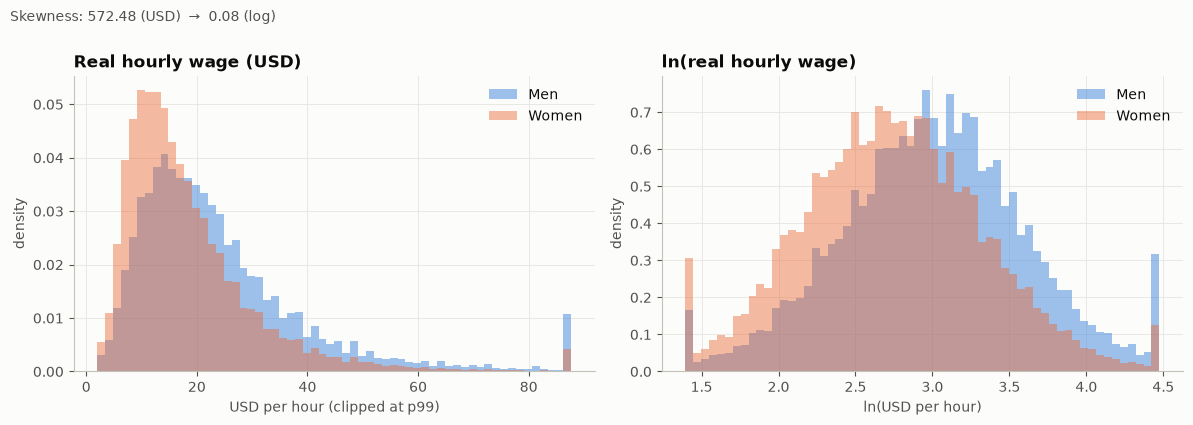

In [36]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
cap = df["realhrwage"].quantile(0.99)
for lab, g in df.groupby("sex_label"):
    axes[0].hist(g["realhrwage"].clip(upper=cap), bins=60, weights=g[W], density=True, histtype="stepfilled",
                 alpha=0.45, color=SEX_COLORS[lab], label=lab)
    axes[1].hist(g[Y], bins=60, weights=g[W], density=True, histtype="stepfilled", alpha=0.45, color=SEX_COLORS[lab], label=lab)
axes[0].set_title("Real hourly wage (USD)"); axes[0].set_xlabel("USD per hour (clipped at p99)")
axes[1].set_title("ln(real hourly wage)"); axes[1].set_xlabel("ln(USD per hour)")
for ax in axes:
    ax.set_ylabel("density"); ax.legend()
skew_raw, skew_log = df["realhrwage"].skew(), df[Y].skew()
fig.suptitle(f"Skewness: {skew_raw:.2f} (USD)  →  {skew_log:.2f} (log)", x=0.01, ha="left", fontsize=10, color=INK2, y=1.0)
savefig("01_wage_distribution")

### Figure 2 — Age, potential experience, weekly hours and weeks worked by sex

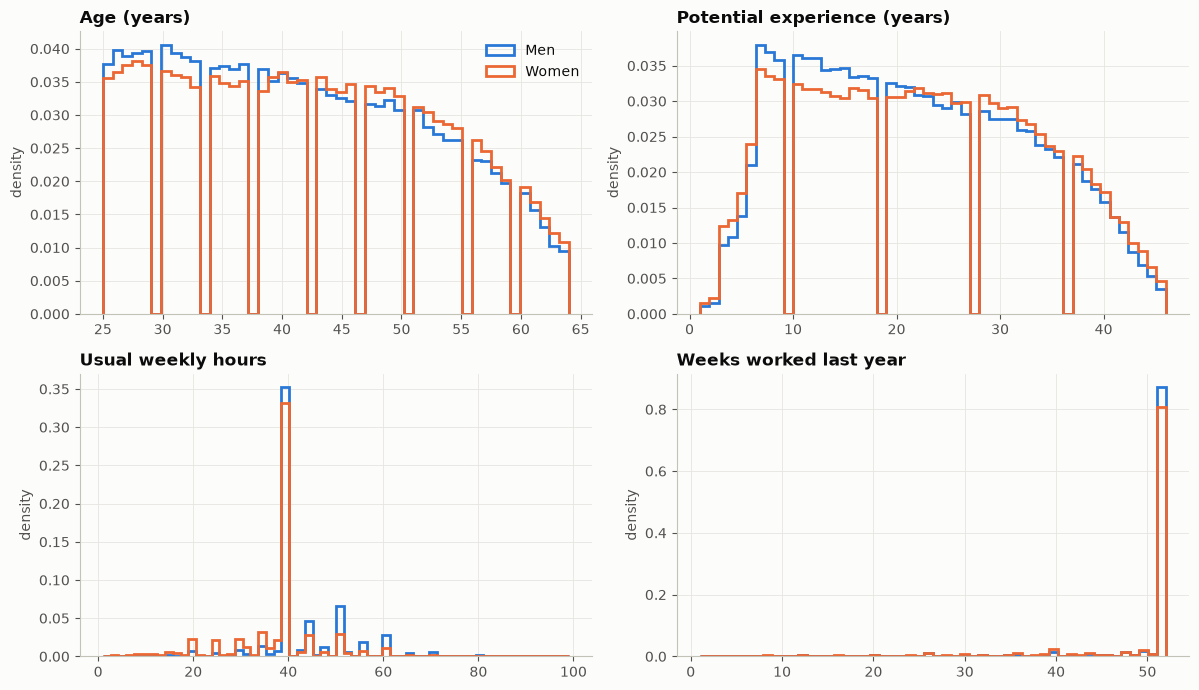

In [37]:
fig, axes = plt.subplots(2, 2, figsize=(12, 7))
for ax, (col, ttl, bins) in zip(axes.ravel(), [("age", "Age (years)", 48), ("potexp", "Potential experience (years)", 50),
                                               ("uhrswork", "Usual weekly hours", 60), ("wkswork1", "Weeks worked last year", 52)]):
    for lab, g in df.groupby("sex_label"):
        ax.hist(g[col], bins=bins, weights=g[W], density=True, histtype="step", linewidth=2, color=SEX_COLORS[lab], label=lab)
    ax.set_title(ttl); ax.set_ylabel("density")
axes[0, 0].legend()
savefig("02_numeric_distributions")

### Figure 3 — Composition of the sample: education and occupation by sex

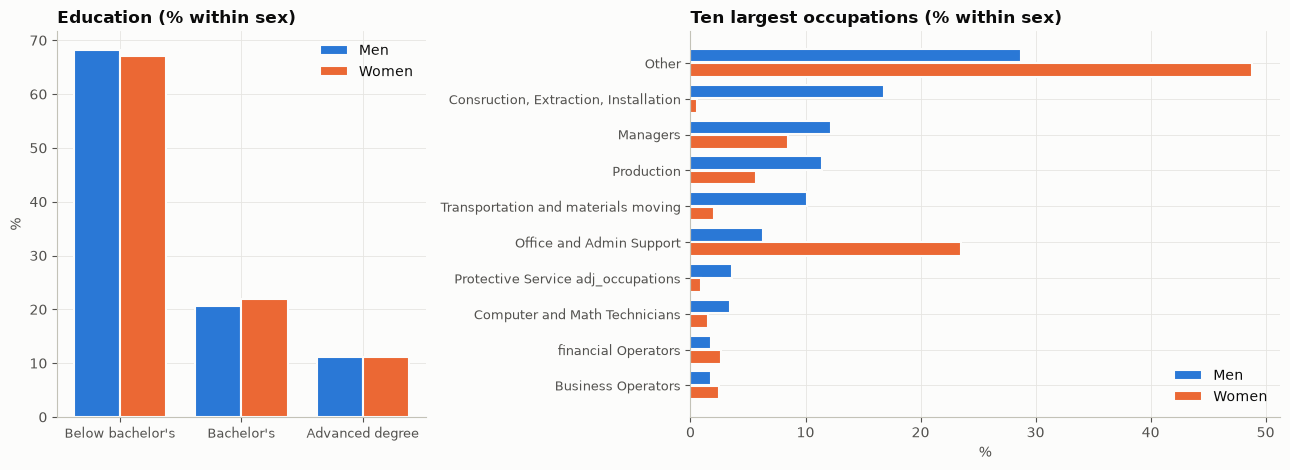

In [38]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.8), gridspec_kw={"width_ratios": [1, 1.6]})
edu_share = (pd.crosstab(df["edu_group"], df["sex_label"], normalize="columns") * 100).loc[edu_order]
grouped_bars(axes[0], edu_share[["Men", "Women"]], [MEN, WOMEN])
axes[0].set_title("Education (% within sex)"); axes[0].set_ylabel("%"); axes[0].legend()
axes[0].tick_params(axis="x", labelsize=9)

if "adj_occ2name" in df.columns:
    top_occ = df["adj_occ2name"].value_counts().head(10).index
    occ_share = (pd.crosstab(df["adj_occ2name"], df["sex_label"], normalize="columns") * 100).loc[top_occ]
    occ_share = occ_share.sort_values("Men")
    y = np.arange(len(occ_share))
    axes[1].barh(y + 0.2, occ_share["Men"], 0.38, color=MEN, edgecolor=SURFACE, linewidth=1.5, label="Men")
    axes[1].barh(y - 0.2, occ_share["Women"], 0.38, color=WOMEN, edgecolor=SURFACE, linewidth=1.5, label="Women")
    axes[1].set_yticks(y); axes[1].set_yticklabels(occ_share.index, fontsize=9)
    axes[1].set_title("Ten largest occupations (% within sex)"); axes[1].set_xlabel("%"); axes[1].legend()
savefig("03_composition_education_occupation")

## 4. Correlation analysis

Pearson correlation is used for the target, with Spearman as a robustness check for the numeric block
(wages and experience have non-linear relations).

In [39]:
corr_cols = [c for c in [Y, "female", "age", "potexp", "uhrswork", "wkswork1", "year", "edu_ord"] if c in df.columns]
pear = df[corr_cols].corr(method="pearson")
spear = df[corr_cols].corr(method="spearman")
display(pd.DataFrame({"Pearson": pear[Y], "Spearman": spear[Y]}).drop(Y).sort_values("Pearson", key=abs, ascending=False))

,Pearson,Spearman
edu_ord,0.4012,0.4017
female,-0.2283,-0.2335
uhrswork,0.1538,0.2154
age,0.1327,0.1396
year,0.1321,0.1131
wkswork1,0.1288,0.1427
potexp,0.0445,0.0537


### Figure 4 — Correlation matrix of the main numeric features

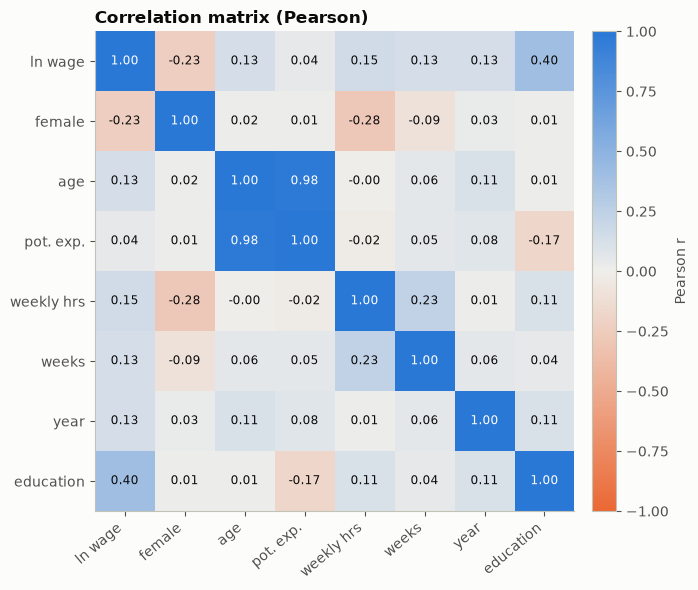

In [40]:
labels = {"ln_realhrwage": "ln wage", "female": "female", "age": "age", "potexp": "pot. exp.", "uhrswork": "weekly hrs",
          "wkswork1": "weeks", "year": "year", "edu_ord": "education"}
fig, ax = plt.subplots(figsize=(7.2, 6))
im = ax.imshow(pear.values, cmap=DIVERGING, vmin=-1, vmax=1)
ax.set_xticks(range(len(pear))); ax.set_yticks(range(len(pear)))
ax.set_xticklabels([labels.get(c, c) for c in pear.columns], rotation=40, ha="right"); ax.set_yticklabels([labels.get(c, c) for c in pear.index])
ax.grid(False)
for i in range(len(pear)):
    for j in range(len(pear)):
        v = pear.values[i, j]
        ax.text(j, i, f"{v:.2f}", ha="center", va="center", fontsize=8.5, color=INK if abs(v) < 0.6 else "white")
cb = fig.colorbar(im, ax=ax, fraction=0.046, pad=0.03); cb.set_label("Pearson r")
ax.set_title("Correlation matrix (Pearson)")
savefig("04_correlation_matrix")

### Figure 5 — Which binary features (occupation, industry, region, demographics …) correlate most with the wage?
Computed over every 0/1 column except wage-derived ones and missing-value indicators. Blue = higher wage, orange = lower.

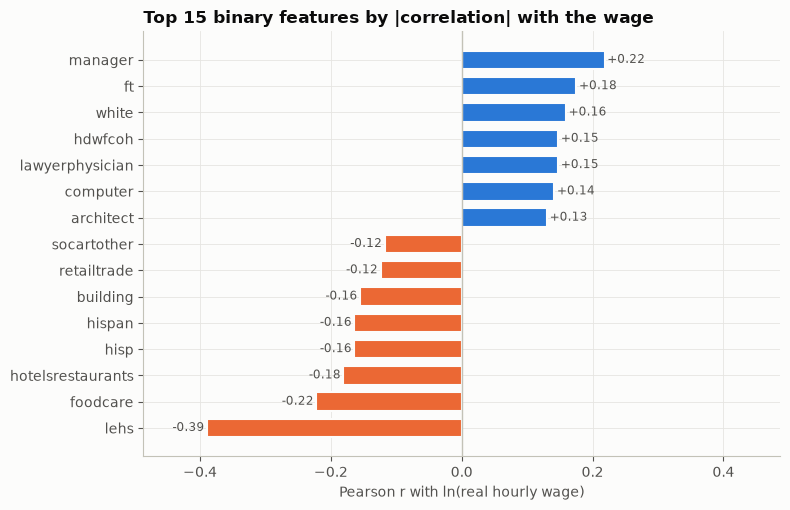

In [41]:
EXCLUDE = {"top_coded", "female", "ba", "adv", "union"}
bin_cols = [c for c in df.columns if c not in EXCLUDE and not c.endswith("_missing") and df[c].dtype != object
            and df[c].nunique() == 2 and set(df[c].unique()) <= {0, 1} and c != Y]
r_bin = df[bin_cols].corrwith(df[Y]).dropna()
if "union" in df.columns and "union_missing" in df.columns:          # union only where it was asked
    obs = df["union_missing"] == 0
    r_bin["union (where asked)"] = df.loc[obs, "union"].corr(df.loc[obs, Y])
r_top = r_bin.reindex(r_bin.abs().sort_values(ascending=False).head(15).index).sort_values()

fig, ax = plt.subplots(figsize=(8, 5.2))
ax.barh(r_top.index, r_top.values, color=[MEN if v > 0 else WOMEN for v in r_top.values], edgecolor=SURFACE, linewidth=1.5, height=0.7)
for yv, v in enumerate(r_top.values):
    ax.text(v + (0.004 if v > 0 else -0.004), yv, f"{v:+.2f}", va="center", ha="left" if v > 0 else "right", fontsize=8.5, color=INK2)
ax.axvline(0, color="#c3c2b7", linewidth=1)
ax.set_xlabel("Pearson r with ln(real hourly wage)"); ax.set_title("Top 15 binary features by |correlation| with the wage")
lim = max(abs(r_top.values)) * 1.25; ax.set_xlim(-lim, lim)
savefig("05_top_binary_correlations")

## 5. RQ1 — How large is the raw gender wage gap and how has it changed (1981 → 2013)?

Gap = % by which women earn less than men. Two weighted measures: the gap in **geometric-mean** hourly wage
(difference of mean log wages) and the gap in **median** hourly wage.

In [42]:
rows = []
for yr, g in df.groupby("year"):
    m, f = g[g["female"] == 0], g[g["female"] == 1]
    d = wmean(m[Y], m[W]) - wmean(f[Y], f[W])
    mm, mf = wmedian(m["realhrwage"], m[W]), wmedian(f["realhrwage"], f[W])
    rows.append({"year": yr, "n": len(g), "log_gap": d, "gap_geomean_%": pct_gap_from_log(d),
                 "gap_median_%": 100 * (1 - mf / mm), "median_wage_men": mm, "median_wage_women": mf})
gap = pd.DataFrame(rows).set_index("year")

trend = stats.linregress(gap.index.values, gap["gap_geomean_%"].values)
k = min(5, max(1, len(gap) // 3))
first_k, last_k = gap["gap_geomean_%"].head(k).mean(), gap["gap_geomean_%"].tail(k).mean()
gap.to_csv(RES_DIR / "gap_by_year.csv")
display(gap.round(3))
print(f"\nTrend of the geometric-mean gap: {trend.slope:+.3f} pp per year (R²={trend.rvalue**2:.2f}, p={fmt_p(trend.pvalue)})")
print(f"Average of first {k} survey years: {first_k:.1f}%  |  last {k}: {last_k:.1f}%")

# overall (pooled, weighted) gaps
m_all, f_all = df[df["female"] == 0], df[df["female"] == 1]
overall_gap_log = pct_gap_from_log(wmean(m_all[Y], m_all[W]) - wmean(f_all[Y], f_all[W]))
overall_gap_med = 100 * (1 - wmedian(f_all["realhrwage"], f_all[W]) / wmedian(m_all["realhrwage"], m_all[W]))
annual_gap_mean = 100 * (1 - wmean(f_all["incwage"], f_all[W]) / wmean(m_all["incwage"], m_all[W]))
annual_gap_med = 100 * (1 - wmedian(f_all["incwage"], f_all[W]) / wmedian(m_all["incwage"], m_all[W]))
print(f"Pooled hourly gap: geometric-mean {overall_gap_log:.1f}% | median {overall_gap_med:.1f}%")
print(f"Pooled ANNUAL wage-income gap (cf. GPG-002, unweighted there): mean {annual_gap_mean:.1f}% | median {annual_gap_med:.1f}%")

,n,log_gap,gap_geomean_%,gap_median_%,median_wage_men,median_wage_women
year,,,,,,
1981,42379,0.4780,38.0020,40.7410,20.0040,11.8540
1990,45033,0.3410,28.8990,29.6000,19.2800,13.5730
1999,37144,0.2730,23.8990,24.7060,19.8710,14.9610
2007,56467,0.2130,19.1780,20.0000,20.6370,16.5090
2009,55617,0.2220,19.8820,19.0480,20.9160,16.9320
2011,53857,0.2010,18.2290,18.3330,20.6040,16.8270
2013,53790,0.1930,17.5470,19.6500,20.6550,16.5970



Trend of the geometric-mean gap: -0.610 pp per year (R²=0.97, p=6.78e-05)
Average of first 2 survey years: 33.5%  |  last 2: 17.9%
Pooled hourly gap: geometric-mean 22.8% | median 24.3%
Pooled ANNUAL wage-income gap (cf. GPG-002, unweighted there): mean 32.8% | median 28.6%


### Figure 6 — The raw hourly gap over time

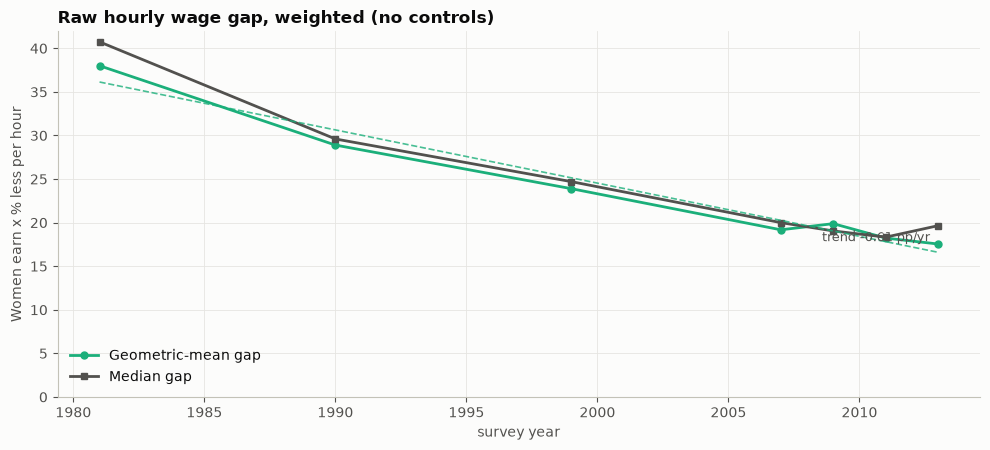

In [43]:
fig, ax = plt.subplots(figsize=(10, 4.6))
ax.plot(gap.index, gap["gap_geomean_%"], color="#1baf7a", marker="o", markersize=5, label="Geometric-mean gap")
ax.plot(gap.index, gap["gap_median_%"], color=INK2, marker="s", markersize=5, label="Median gap")
ax.plot(gap.index, trend.intercept + trend.slope * gap.index.values, color="#1baf7a", linestyle="--", linewidth=1.2, alpha=0.8)
ax.annotate(f"trend {trend.slope:+.2f} pp/yr", (gap.index[-1], trend.intercept + trend.slope * gap.index[-1]),
            textcoords="offset points", xytext=(-6, 8), ha="right", fontsize=9, color=INK2)
ax.set_ylabel("Women earn x % less per hour"); ax.set_xlabel("survey year"); ax.set_ylim(bottom=0)
ax.set_title("Raw hourly wage gap, weighted (no controls)"); ax.legend(loc="lower left")
savefig("06_gap_over_time")

## 6. Education, experience and occupation

### Figure 7 — Median hourly wage by education and sex

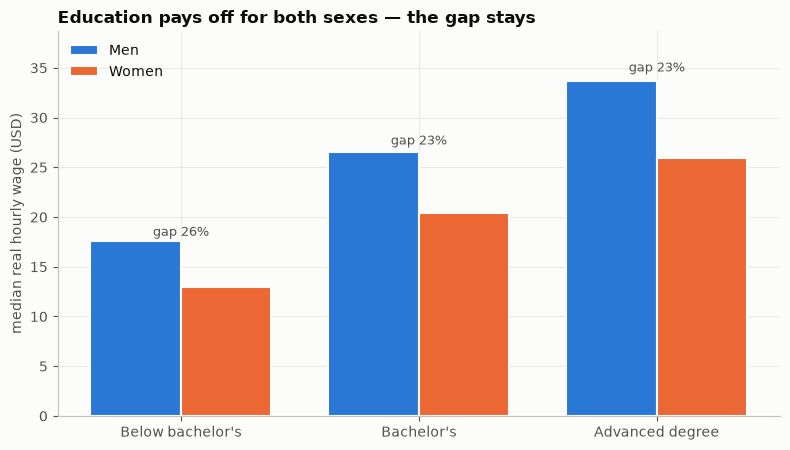

In [44]:
rows = []
for edu, g in df.groupby("edu_group"):
    for lab, gg in g.groupby("sex_label"):
        rows.append({"edu": edu, "sex": lab, "median_wage": wmedian(gg["realhrwage"], gg[W])})
edu_med = pd.DataFrame(rows).pivot(index="edu", columns="sex", values="median_wage").loc[edu_order]
edu_gap = 100 * (1 - edu_med["Women"] / edu_med["Men"])

fig, ax = plt.subplots(figsize=(8, 4.6))
grouped_bars(ax, edu_med[["Men", "Women"]], [MEN, WOMEN])
for i, (e, v) in enumerate(edu_gap.items()):
    ax.text(i, max(edu_med.loc[e]) * 1.03, f"gap {v:.0f}%", ha="center", fontsize=9, color=INK2)
ax.set_ylabel("median real hourly wage (USD)"); ax.set_title("Education pays off for both sexes — the gap stays"); ax.legend(loc="upper left")
ax.set_ylim(0, edu_med.to_numpy().max() * 1.15)
savefig("07_wage_by_education_sex")

### Figure 8 — Experience profile and the gap by experience

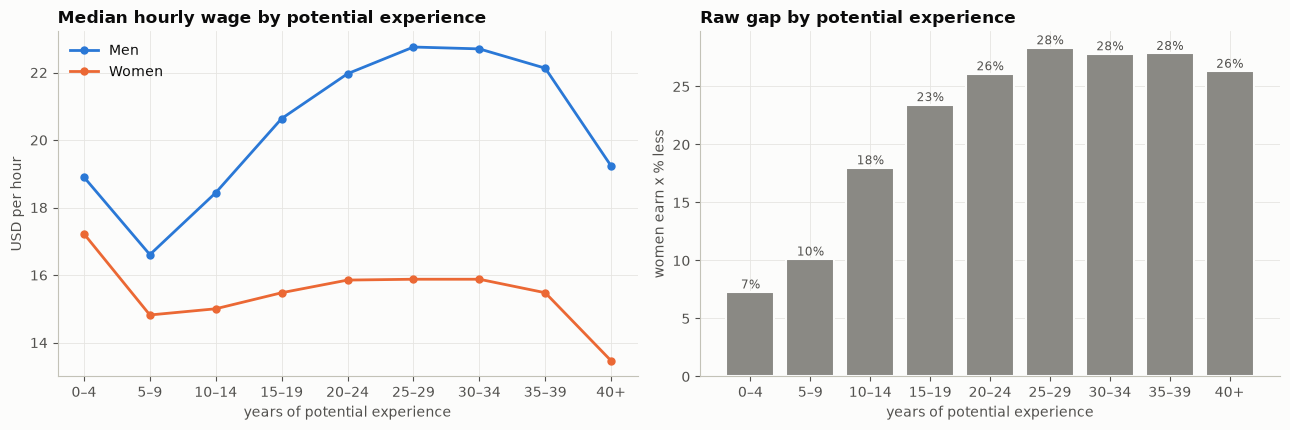

In [45]:
bins = [-1, 4, 9, 14, 19, 24, 29, 34, 39, 200]
blabels = ["0–4", "5–9", "10–14", "15–19", "20–24", "25–29", "30–34", "35–39", "40+"]
df["exp_bin"] = pd.cut(df["potexp"], bins=bins, labels=blabels)
rows = []
for (b, lab), g in df.groupby(["exp_bin", "sex_label"], observed=True):
    rows.append({"exp_bin": b, "sex": lab, "mean_ln": wmean(g[Y], g[W]), "median_wage": wmedian(g["realhrwage"], g[W]), "n": len(g)})
exp_t = pd.DataFrame(rows)
prof = exp_t.pivot(index="exp_bin", columns="sex", values="median_wage").reindex(blabels)
exp_gap = pct_gap_from_log(exp_t.pivot(index="exp_bin", columns="sex", values="mean_ln").reindex(blabels).eval("Men - Women"))

fig, axes = plt.subplots(1, 2, figsize=(13, 4.4))
for lab in ["Men", "Women"]:
    axes[0].plot(blabels, prof[lab], marker="o", markersize=5, color=SEX_COLORS[lab], label=lab)
axes[0].set_title("Median hourly wage by potential experience"); axes[0].set_ylabel("USD per hour"); axes[0].set_xlabel("years of potential experience"); axes[0].legend()
axes[1].bar(blabels, exp_gap.values, color="#8a8984", edgecolor=SURFACE, linewidth=1.5)
for i, v in enumerate(exp_gap.values):
    axes[1].text(i, v + 0.3, f"{v:.0f}%", ha="center", fontsize=8.5, color=INK2)
axes[1].set_title("Raw gap by potential experience"); axes[1].set_ylabel("women earn x % less"); axes[1].set_xlabel("years of potential experience")
savefig("08_experience_profile_and_gap")

### Figure 9 — Occupational segregation: female share vs. median wage by occupation

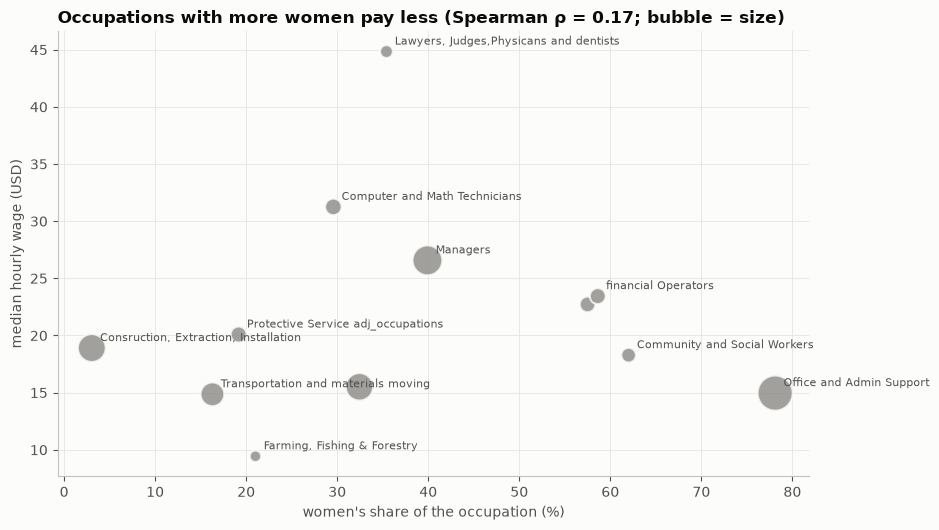

,n,female_share_%,median_wage
occupation,,,
Office and Admin Support,50635,78.1100,14.9600
Community and Social Workers,6025,62.0100,18.2800
financial Operators,7702,58.6200,23.4400
Business Operators,7327,57.5000,22.7200
Managers,35696,39.9100,26.5700
"Lawyers, Judges,Physicans and dentists",3835,35.4100,44.8400
Production,29732,32.4400,15.5100
Computer and Math Technicians,8602,29.5700,31.2500
"Farming, Fishing & Forestry",2360,21.0200,9.4400


In [46]:
if "adj_occ2name" in df.columns:
    rows = []
    for occ, g in df.groupby("adj_occ2name"):
        if len(g) >= 200 and occ != OTHER_OCC:
            rows.append({"occupation": occ, "n": len(g), "female_share_%": 100 * g["female"].mean(), "median_wage": wmedian(g["realhrwage"], g[W])})
    occ_t = pd.DataFrame(rows).set_index("occupation")
    rho, p_rho = stats.spearmanr(occ_t["female_share_%"], occ_t["median_wage"])
    occ_t.sort_values("median_wage", ascending=False).to_csv(RES_DIR / "occupation_table.csv")

    fig, ax = plt.subplots(figsize=(9.5, 5.4))
    ax.scatter(occ_t["female_share_%"], occ_t["median_wage"], s=occ_t["n"] / occ_t["n"].max() * 600 + 40, color="#8a8984",
               alpha=0.8, edgecolor=SURFACE, linewidth=1.5)
    label_idx = set(occ_t["median_wage"].nlargest(4).index) | set(occ_t["median_wage"].nsmallest(3).index) | \
                set(occ_t["female_share_%"].nlargest(3).index) | set(occ_t["female_share_%"].nsmallest(3).index)
    for occ in label_idx:
        ax.annotate(occ, (occ_t.loc[occ, "female_share_%"], occ_t.loc[occ, "median_wage"]), textcoords="offset points", xytext=(6, 5), fontsize=8, color=INK2)
    ax.set_xlabel("women's share of the occupation (%)"); ax.set_ylabel("median hourly wage (USD)")
    ax.set_title(f"Occupations with more women pay less (Spearman ρ = {rho:.2f}; bubble = size)")
    savefig("09_occupational_segregation")
    display(occ_t.sort_values("female_share_%", ascending=False).round(2))
else:
    rho, p_rho = np.nan, np.nan
    print("adj_occ2name not available — skipping")

## 7. Statistical tests

> With ~340k observations almost **every** test is "significant" (tiny p-values). Therefore each test is reported with an
> **effect size** (Cohen's d, η², Cramér's V) — the effect size says whether a difference *matters*.

### 7.1 Wage by sex — Welch t-test, Mann–Whitney U, Cohen's d
H₀: mean ln wage of men = mean ln wage of women.

In [47]:
a, b = df.loc[df["female"] == 0, Y].values, df.loc[df["female"] == 1, Y].values
t_stat, p_t = stats.ttest_ind(a, b, equal_var=False)
u_stat, p_u = stats.mannwhitneyu(a, b, alternative="two-sided")
d = cohens_d(a, b)
ci = stats.t.interval(0.95, len(a) + len(b) - 2, loc=a.mean() - b.mean(), scale=np.sqrt(a.var(ddof=1) / len(a) + b.var(ddof=1) / len(b)))
print(f"Men mean ln wage {a.mean():.3f} | Women {b.mean():.3f} | difference {a.mean() - b.mean():.3f} (95% CI {ci[0]:.3f}..{ci[1]:.3f})")
print(f"Welch t = {t_stat:.1f}, p = {fmt_p(p_t)} | Mann–Whitney U p = {fmt_p(p_u)} | Cohen's d = {d:.3f}")
sex_test = {"t": t_stat, "p_t": p_t, "p_u": p_u, "d": d, "diff": a.mean() - b.mean()}

Men mean ln wage 3.009 | Women 2.732 | difference 0.277 (95% CI 0.273..0.281)
Welch t = 137.6, p = < 1e-300 | Mann–Whitney U p = < 1e-300 | Cohen's d = 0.469


### 7.2 One-way ANOVA — ln wage across groups of a categorical factor
For each factor: ANOVA F-test, **η²** (share of the variance of ln wage explained by the factor) and the non-parametric
Kruskal–Wallis test as a robustness check (the wage is not exactly normal within groups).

In [48]:
def anova_by(col, data=df, y=Y, min_n=30):
    data = data[[col, y]].dropna()
    sizes = data.groupby(col)[y].transform("size")
    data = data[sizes >= min_n]
    groups = [g[y].values for _, g in data.groupby(col)]
    F, p = stats.f_oneway(*groups)
    H, p_kw = stats.kruskal(*groups)
    grand = data[y].mean()
    ss_b = sum(len(g) * (g.mean() - grand) ** 2 for g in groups)
    ss_t = ((data[y] - grand) ** 2).sum()
    return {"factor": col, "groups": len(groups), "F": F, "p_value": p, "eta_squared": ss_b / ss_t, "kruskal_H": H, "p_kruskal": p_kw}

factors = [c for c in ["edu_group", "adj_occ2name", "region", "race", "marst", "classwkr", "sex_label", "year"] if c in df.columns]
anova_tbl = pd.DataFrame([anova_by(c) for c in factors]).set_index("factor").sort_values("eta_squared", ascending=False)
anova_tbl.to_csv(RES_DIR / "anova_results.csv")
disp = anova_tbl.copy(); disp["p_value"] = disp["p_value"].map(fmt_p); disp["p_kruskal"] = disp["p_kruskal"].map(fmt_p)
display(disp)

# Levene: are variances equal across education groups?
lev = stats.levene(*[g[Y].values for _, g in smp.groupby("edu_group")])
print(f"\nLevene test (education groups, 60k sample): W = {lev.statistic:.1f}, p = {fmt_p(lev.pvalue)}  ->  variances differ, so Kruskal-Wallis / Welch-type checks above matter")

,groups,F,p_value,eta_squared,kruskal_H,p_kruskal
factor,,,,,,
edu_group,3,"33,696.3827",< 1e-300,0.1637,"55,834.1493",< 1e-300
adj_occ2name,13,"4,251.6546",< 1e-300,0.1291,"42,971.1048",< 1e-300
sex_label,2,"18,932.2168",< 1e-300,0.0521,"18,772.1322",< 1e-300
race,4,"4,314.1340",< 1e-300,0.0362,"13,057.9514",< 1e-300
marst,6,"1,755.1519",< 1e-300,0.0249,"8,750.7971",< 1e-300
year,7,"1,069.5962",< 1e-300,0.0183,"5,843.6262",< 1e-300
classwkr,7,867.0729,< 1e-300,0.0149,"6,075.4783",< 1e-300
region,9,598.1032,< 1e-300,0.0137,"4,751.0626",< 1e-300



Levene test (education groups, 60k sample): W = 2.9, p = 0.0542  ->  variances differ, so Kruskal-Wallis / Welch-type checks above matter


**Reading η²:** ≈ 0.01 small, ≈ 0.06 medium, ≈ 0.14+ large (Cohen). Factors at the top of the table separate wages most.

### 7.3 Post-hoc: Tukey HSD for education groups (60k random sample)

In [49]:
tuk = pairwise_tukeyhsd(smp[Y], smp["edu_group"], alpha=0.05)
tuk_tbl = pd.DataFrame(tuk._results_table.data[1:], columns=tuk._results_table.data[0])
display(tuk_tbl)
tukey_all_differ = bool(tuk_tbl["reject"].astype(bool).all())

,group1,group2,meandiff,p-adj,lower,upper,reject
0,Advanced degree,Bachelor's,-0.2499,0.0000,-0.2695,-0.2302,True
1,Advanced degree,Below bachelor's,-0.6667,0.0000,-0.6838,-0.6496,True
2,Bachelor's,Below bachelor's,-0.4169,0.0000,-0.4301,-0.4036,True


### 7.4 Two-way ANOVA: sex × education (does the gap differ by education level?)

In [50]:
m2 = smf.ols(f"{Y} ~ C(female) * C(edu_f)", data=df).fit()
two_way = sm.stats.anova_lm(m2, typ=2)
two_way["eta_sq_partial"] = two_way["sum_sq"] / (two_way["sum_sq"] + two_way.loc["Residual", "sum_sq"])
two_disp = two_way.copy(); two_disp["PR(>F)"] = two_disp["PR(>F)"].map(lambda v: fmt_p(v) if pd.notna(v) else "")
display(two_disp)

,sum_sq,df,F,PR(>F),eta_sq_partial
C(female),"6,825.4127",1.0000,"23,783.1306",< 1e-300,0.0646
C(edu_f),"20,923.7955",2.0000,"36,454.4522",< 1e-300,0.1748
C(female):C(edu_f),39.4709,2.0000,68.7682,1.38e-30,0.0004
Residual,"98,803.6412","344,281.0000",NaN,,0.5000


### 7.5 χ² test of independence: sex × occupation (occupational segregation)

In [51]:
if "adj_occ2name" in df.columns:
    ct = pd.crosstab(df["adj_occ2name"], df["female"])
    chi2, p_chi, dof, _ = stats.chi2_contingency(ct)
    V = cramers_v(ct)
    print(f"χ² = {chi2:,.0f}, dof = {dof}, p = {fmt_p(p_chi)}, Cramér's V = {V:.3f}  (0.1 small, 0.3 medium, 0.5 large)")
else:
    chi2, p_chi, dof, V = np.nan, np.nan, np.nan, np.nan

χ² = 71,454, dof = 12, p = < 1e-300, Cramér's V = 0.456  (0.1 small, 0.3 medium, 0.5 large)


## 8. First look at RQ2–RQ4 — how much of the gap do observable characteristics explain?

A **Mincer-type OLS** on ln(real hourly wage), adding blocks of controls step by step; the `female` coefficient tells how
much lower women's log wage is *given* the controls (heteroskedasticity-robust SEs). `1 − exp(β)` converts it to
"women earn x % less". This is a descriptive preview — the formal modelling and validation are later tasks.

Set `REG_SAMPLE = 100_000` below if the regressions are too slow/heavy on your laptop.

In [52]:
REG_SAMPLE = None
reg = df if REG_SAMPLE is None else df.sample(min(REG_SAMPLE, len(df)), random_state=RANDOM_STATE)

blocks = [("M0 raw (sex only)", ["female"]),
          ("M1 + survey year", ["C(year)"]),
          ("M2 + education & experience", ["C(edu_f)", "potexp", "I(potexp**2)"]),
          ("M3 + hours & weeks", ["uhrswork", "wkswork1"]),
          ("M4 + occupation & region", [t for t, c in [("C(adj_occ2name)", "adj_occ2name"), ("C(region)", "region")] if c in df.columns]),
          ("M5 + race & marital status", [t for t, c in [("C(race)", "race"), ("C(marst)", "marst")] if c in df.columns])]
terms, results = [], []
for name, add in blocks:
    terms += add
    fit = smf.ols(f"{Y} ~ " + " + ".join(terms), data=reg).fit(cov_type="HC1")
    b, se = fit.params["female"], fit.bse["female"]
    results.append({"model": name, "n_params": int(fit.df_model), "R2": fit.rsquared, "female_coef": b, "se": se,
                    "ci_low": b - 1.96 * se, "ci_high": b + 1.96 * se, "p_value": fit.pvalues["female"],
                    "women_earn_less_%": 100 * (1 - np.exp(b))})
    print(f"{name:32s} R²={fit.rsquared:.3f}  female coef {b:+.4f}  -> women earn {100 * (1 - np.exp(b)):.1f}% less")
res = pd.DataFrame(results).set_index("model")
b0, b_last = res["female_coef"].iloc[0], res["female_coef"].iloc[-1]
explained_share = 100 * (1 - b_last / b0)
res.to_csv(RES_DIR / "regression_models.csv")
res_disp = res.copy(); res_disp["p_value"] = res_disp["p_value"].map(fmt_p)
display(res_disp)
print(f"\nShare of the raw (log) gap explained by all controls: {explained_share:.0f}%  |  unexplained: {100 - explained_share:.0f}%")

M0 raw (sex only)                R²=0.052  female coef -0.2767  -> women earn 24.2% less
M1 + survey year                 R²=0.072  female coef -0.2818  -> women earn 24.6% less
M2 + education & experience      R²=0.251  female coef -0.2848  -> women earn 24.8% less
M3 + hours & weeks               R²=0.257  female coef -0.2669  -> women earn 23.4% less
M4 + occupation & region         R²=0.313  female coef -0.2450  -> women earn 21.7% less
M5 + race & marital status       R²=0.335  female coef -0.2403  -> women earn 21.4% less


,n_params,R2,female_coef,se,ci_low,ci_high,p_value,women_earn_less_%
model,,,,,,,,
M0 raw (sex only),1,0.0521,-0.2767,0.0020,-0.2806,-0.2727,< 1e-300,24.1706
M1 + survey year,7,0.0723,-0.2818,0.0020,-0.2857,-0.2779,< 1e-300,24.5544
M2 + education & experience,11,0.2505,-0.2848,0.0018,-0.2883,-0.2813,< 1e-300,24.7825
M3 + hours & weeks,13,0.2571,-0.2669,0.0019,-0.2706,-0.2633,< 1e-300,23.4265
M4 + occupation & region,33,0.3135,-0.2450,0.0020,-0.2489,-0.2410,< 1e-300,21.7285
M5 + race & marital status,41,0.3346,-0.2403,0.0020,-0.2443,-0.2364,< 1e-300,21.3643



Share of the raw (log) gap explained by all controls: 13%  |  unexplained: 87%


### Figure 10 — The `female` coefficient shrinks as controls are added, but does not vanish

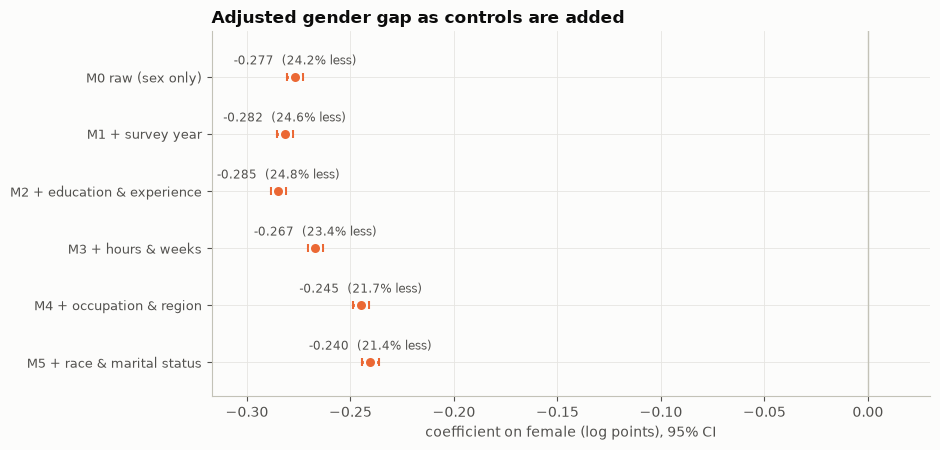

In [53]:
fig, ax = plt.subplots(figsize=(9.5, 4.6))
y_pos = np.arange(len(res))[::-1]
ax.errorbar(res["female_coef"], y_pos, xerr=[res["female_coef"] - res["ci_low"], res["ci_high"] - res["female_coef"]],
            fmt="o", color=WOMEN, ecolor=WOMEN, elinewidth=2, capsize=3, markersize=8, markeredgecolor=SURFACE, markeredgewidth=1.5)
for yv, (coef, pg) in zip(y_pos, zip(res["female_coef"], res["women_earn_less_%"])):
    ax.text(coef, yv + 0.22, f"{coef:+.3f}  ({pg:.1f}% less)", ha="center", fontsize=8.5, color=INK2)
ax.axvline(0, color="#c3c2b7", linewidth=1)
ax.set_yticks(y_pos); ax.set_yticklabels(res.index, fontsize=9)
ax.set_xlabel("coefficient on female (log points), 95% CI"); ax.set_title("Adjusted gender gap as controls are added")
lo = min(res["ci_low"].min(), -0.05); ax.set_xlim(lo * 1.1, 0.03); ax.set_ylim(-0.6, len(res) - 0.2)
savefig("10_gap_with_controls")

### 8.1 RQ4 preview — predictive power of feature blocks and differences between men and women
* R² gain from each block (the order of adding matters; this is a rough guide, formal importance comes with the models).
* The same specification fitted **separately** for men and women.

In [54]:
r2_gain = res["R2"].diff().fillna(res["R2"].iloc[0]).rename("R2 gain").to_frame()
r2_gain["cumulative R2"] = res["R2"]
display(r2_gain)

spec = " + ".join(terms[1:])                         # everything except `female`
sep = {}
for lab, flag in [("Men", 0), ("Women", 1)]:
    sub = reg[reg["female"] == flag]
    fit = smf.ols(f"{Y} ~ {spec}", data=sub).fit()
    sep[lab] = {"n": len(sub), "R2": fit.rsquared,
                "return to bachelor's (log pts)": fit.params.get("C(edu_f)[T.b_BA]", np.nan),
                "return to advanced degree": fit.params.get("C(edu_f)[T.c_Advanced]", np.nan),
                "weekly hours (per hour)": fit.params.get("uhrswork", np.nan),
                "potexp (per year)": fit.params.get("potexp", np.nan)}
sep_tbl = pd.DataFrame(sep)
display(sep_tbl)

,R2 gain,cumulative R2
model,,
M0 raw (sex only),0.0521,0.0521
M1 + survey year,0.0202,0.0723
M2 + education & experience,0.1782,0.2505
M3 + hours & weeks,0.0065,0.2571
M4 + occupation & region,0.0564,0.3135
M5 + race & marital status,0.0211,0.3346


,Men,Women
n,"175,911.0000","168,376.0000"
R2,0.3248,0.2988
return to bachelor's (log pts),0.3369,0.3763
return to advanced degree,0.5013,0.6040
weekly hours (per hour),-0.0012,0.0010
potexp (per year),0.0335,0.0167


## 9. Conclusions
Each conclusion is generated from the results above (numbers update automatically with the data).

In [55]:
conclusions = []
sig = lambda p: p < 0.05

# 1 — raw gap
smaller = annual_gap_mean > overall_gap_log
conclusions.append(("The raw gender wage gap is substantial" + (" and persists on an hourly basis" if overall_gap_log > 5 else ""),
    f"On a weighted basis women earn {overall_gap_log:.1f}% less per hour than men in geometric-mean terms "
    f"({overall_gap_med:.1f}% at the median). On annual wage income the gap is {annual_gap_mean:.1f}% (mean) / {annual_gap_med:.1f}% (median). "
    + ("Because the hourly gap is smaller than the annual gap, part of the annual gap comes from fewer hours/weeks, "
       "but the remainder is not explained by hours alone (RQ1)." if smaller else
       "The hourly gap is not smaller than the annual gap, so hours worked do not explain it (RQ1).")))

# 2 — trend
direction = ("narrowed" if trend.slope < 0 and sig(trend.pvalue) else
             "widened" if trend.slope > 0 and sig(trend.pvalue) else "showed no statistically clear trend")
conclusions.append((f"The gap {direction} between {int(gap.index.min())} and {int(gap.index.max())}",
    f"The weighted geometric-mean gap averaged {first_k:.1f}% in the first {k} survey years and {last_k:.1f}% in the last {k}; "
    f"the linear trend is {trend.slope:+.2f} percentage points per year (R² = {trend.rvalue**2:.2f}, p = {fmt_p(trend.pvalue)}) (RQ1)."))

# 3 — distribution -> log target
conclusions.append(("Wages are " + ("strongly right-skewed" if skew_raw > 1 else "skewed") + " — the log of the hourly wage is a better target",
    f"Skewness of the hourly wage is {skew_raw:.2f} versus {skew_log:.2f} for ln(wage). "
    f"{'The log target is much closer to symmetric, and ' if abs(skew_log) < abs(skew_raw) else ''}regression coefficients on it read as approximate percentage differences."))

# 4 — factors by eta2
others = anova_tbl.drop(index=[i for i in ["sex_label", "year"] if i in anova_tbl.index])
top3 = others.head(3)
txt = "; ".join(f"{i} η² = {r.eta_squared:.3f}" for i, r in top3.iterrows())
e_sex = anova_tbl.loc["sex_label", "eta_squared"] if "sex_label" in anova_tbl.index else np.nan
low = others.index[others["p_value"] >= 0.05].tolist()
conclusions.append((f"{others.index[0]} and {others.index[1]} are the categorical factors that separate wages most",
    f"One-way ANOVA (η² = share of variance in ln wage explained): {txt}. For comparison, sex alone has η² = {e_sex:.3f} "
    f"(Cohen's d = {sex_test['d']:.2f}). Kruskal–Wallis gives the same ranking. "
    + ("Factors without a significant effect: " + ", ".join(low) + ". " if low else "")
    + (f"Tukey HSD: all pairs of education groups differ significantly (RQ4)." if tukey_all_differ else
       "Tukey HSD: not every pair of education groups differs significantly (RQ4).")))

# 5 — segregation
direction5 = "pay less" if rho < 0 else "pay more"
conclusions.append((f"Men and women are distributed very unevenly across occupations; occupations with more women {direction5}",
    f"χ² test of sex × occupation: Cramér's V = {V:.2f} (p {fmt_p(p_chi)}); the Spearman correlation between an occupation's female share "
    f"and its median hourly wage is ρ = {rho:.2f}. Occupational segregation is therefore a candidate explanation of part of the gap (RQ2)."))

# 6 — experience
g_first, g_last = exp_gap.iloc[0], exp_gap.iloc[5] if len(exp_gap) > 5 else exp_gap.iloc[-1]
if g_last > g_first + 1:
    t6, d6 = "The gap grows with career length", "Wage profiles of men rise more steeply with experience than those of women (Figure 8)"
elif g_last < g_first - 1:
    t6, d6 = "The gap is smaller among more experienced workers", "Wage profiles of women catch up with those of men with experience (Figure 8)"
else:
    t6, d6 = "The gap is roughly constant across experience levels", "Wage profiles of men and women have similar shapes (Figure 8)"
conclusions.append((t6,
    f"The raw gap is {g_first:.1f}% for workers with 0–4 years of potential experience and {g_last:.1f}% at 25–29 years. {d6} (RQ2/RQ4)."))

# 7 — education
p_int = two_way.loc['C(female):C(edu_f)', 'PR(>F)']
conclusions.append(("More education raises wages for both sexes, but a gap remains at every education level",
    f"Median-wage gap by education: " + ", ".join(f"{e} {v:.0f}%" for e, v in edu_gap.items()) +
    f". The two-way ANOVA interaction sex × education is {'significant' if sig(p_int) else 'not significant'} "
    f"(p {fmt_p(p_int)}), i.e. the gap {'differs' if sig(p_int) else 'does not differ clearly'} by education level (partial η² of the interaction = "
    f"{two_way.loc['C(female):C(edu_f)', 'eta_sq_partial']:.4f})."))

# 8 — regression preview
p_last = res['p_value'].iloc[-1]
conclusions.append(("Observable characteristics " + ("explain part of the gap" if explained_share > 5 else "explain little of the gap") +
                    (", and sex remains a significant predictor" if sig(p_last) else ", and sex is no longer significant"),
    f"The OLS coefficient on `female` moves from {b0:+.3f} (raw, {res['women_earn_less_%'].iloc[0]:.1f}% less) to {b_last:+.3f} "
    f"({res['women_earn_less_%'].iloc[-1]:.1f}% less) after controlling for year, education, experience, hours, occupation, region, race and marital status. "
    f"The controls account for roughly {explained_share:.0f}% of the raw log gap; the remaining {100 - explained_share:.0f}% is unexplained by these variables "
    f"(p {fmt_p(p_last)}). " + ("This is consistent with RQ3. " if sig(p_last) and b_last < 0 else "RQ3 is not supported in this specification. ") +
    "It is a statistical association, not proof of discrimination, since unobserved factors may matter (RQ2/RQ3)."))

# 9 — correlations
top_corr = r_bin.reindex(r_bin.abs().sort_values(ascending=False).head(3).index)
num_corr = pear[Y].drop([Y, "female"]).abs().sort_values(ascending=False)
conclusions.append(("Which features carry the linear signal",
    f"Strongest numeric correlates of ln wage: " + ", ".join(f"{labels.get(i, i)} (r = {pear.loc[Y, i]:+.2f})" for i in num_corr.head(3).index) +
    f". Strongest binary features: " + ", ".join(f"{i} (r = {v:+.2f})" for i, v in top_corr.items()) +
    f". `female` itself correlates r = {pear.loc[Y, 'female']:+.2f} with the log wage (RQ4)."))

# 10 — top-coding and testing caution
tc = df.groupby("sex_label")["top_coded"].mean() * 100 if "top_coded" in df.columns else None
tc_txt = (f"{tc['Men']:.1f}% of men versus {tc['Women']:.1f}% of women are at the CPS top-code; because of this censoring the measured gap "
          f"is {'probably understated' if tc['Men'] > tc['Women'] else 'not obviously biased in one direction'}. ") if tc is not None else ""
conclusions.append(("Data caveats: top-coding and very large N",
    tc_txt + f"With ~{len(df) // 1000}k observations tiny differences become 'statistically significant', so conclusions rely on effect sizes "
    "(d, η², Cramér's V, coefficient size) rather than p-values alone. The Mincer regression is descriptive and omits unobservables "
    "(e.g. job tenure, career interruptions)."))

share_other = 100 * (df["adj_occ2name"] == OTHER_OCC).mean()
conclusions.append(("Occupation is only partly captured by `adj_occ2name`",
    f"{share_other:.0f}% of workers fall into the catch-all group '{OTHER_OCC}' (the source field is empty for them; this group contains "
    f"e.g. sales, education, healthcare and food-service jobs and is {100 * df.loc[df['adj_occ2name'] == OTHER_OCC, 'female'].mean():.0f}% female). "
    f"Occupational segregation and the share of the gap explained by occupation are therefore understated; a finer occupation variable "
    f"(from `occ1990` or the occupation dummies) is planned in GPG-005 (RQ2)."))

for i, (title, body) in enumerate(conclusions, 1):
    print(f"{i}. {title}\n   {body}\n")

1. The raw gender wage gap is substantial and persists on an hourly basis
   On a weighted basis women earn 22.8% less per hour than men in geometric-mean terms (24.3% at the median). On annual wage income the gap is 32.8% (mean) / 28.6% (median). Because the hourly gap is smaller than the annual gap, part of the annual gap comes from fewer hours/weeks, but the remainder is not explained by hours alone (RQ1).

2. The gap narrowed between 1981 and 2013
   The weighted geometric-mean gap averaged 33.5% in the first 2 survey years and 17.9% in the last 2; the linear trend is -0.61 percentage points per year (R² = 0.97, p = 6.78e-05) (RQ1).

3. Wages are strongly right-skewed — the log of the hourly wage is a better target
   Skewness of the hourly wage is 572.48 versus 0.08 for ln(wage). The log target is much closer to symmetric, and regression coefficients on it read as approximate percentage differences.

4. edu_group and adj_occ2name are the categorical factors that separate wages mos

### Write findings to `docs/results/GPG-004_findings.md`
Paste the content into the *Proposed Solution* section of `docs/GPG-004.md`.

In [56]:
fig_files = sorted(p.name for p in FIG_DIR.glob("*.png"))
md = ["# GPG-004 — auto-generated findings (from `notebooks/GPG-004_eda.ipynb`)", "", "## Conclusions", ""]
for i, (title, body) in enumerate(conclusions, 1):
    md += [f"{i}. **{title}.** {body}", ""]
md += ["## Key statistical tests", "",
       f"- Welch t-test (ln wage, men vs women): t = {sex_test['t']:.1f}, p {fmt_p(sex_test['p_t'])}; Mann–Whitney p {fmt_p(sex_test['p_u'])}; Cohen's d = {sex_test['d']:.3f}",
       "- One-way ANOVA (η² per factor):", ""]
md += ["  | Factor | groups | F | η² | p |", "  |---|---|---|---|---|"]
for fct, r in anova_tbl.iterrows():
    md.append(f"  | {fct} | {int(r.groups)} | {r.F:,.0f} | {r.eta_squared:.3f} | {fmt_p(r.p_value)} |")
md += ["", f"- Two-way ANOVA sex × education interaction: p {fmt_p(two_way.loc['C(female):C(edu_f)', 'PR(>F)'])}",
       f"- χ² sex × occupation: Cramér's V = {V:.3f}", "", "## OLS preview: `female` coefficient as controls are added", "",
       "| Model | R² | female coef | women earn less |", "|---|---|---|---|"]
for name, r in res.iterrows():
    md.append(f"| {name} | {r.R2:.3f} | {r.female_coef:+.3f} | {r['women_earn_less_%']:.1f}% |")
md += ["", "## Figures (`docs/figures/GPG-004/`)", ""] + [f"- `{f}`" for f in fig_files]
(RES_DIR / "GPG-004_findings.md").write_text("\n".join(md) + "\n", encoding="utf-8")
print("Wrote", RES_DIR / "GPG-004_findings.md", "|", len(fig_files), "figures in", FIG_DIR)

Wrote c:\Users\User\Data-mining-Final-Project\docs\results\GPG-004_findings.md | 10 figures in c:\Users\User\Data-mining-Final-Project\docs\figures\GPG-004
